GGNN -> LLM + Transformer


In [ ]:
!sudo apt-get update -y
!sudo apt-get install python3.10 python3.10-distutils -y
!sudo update-alternatives --install /usr/bin/python3 python3 /usr/bin/python3.10 1

!wget https://bootstrap.pypa.io/get-pip.py -O get-pip.py
!python3 get-pip.py

!python3 --version


Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:5 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:9 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:10 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading packag

In [ ]:
# =======================
# CELL 1 — SETUP PYTORCH + PYTORCH GEOMETRIC (FULL, STABLE)
#                 CHO PIPELINE GGNN → LLM + TRANSFORMER
# =======================

import sys, subprocess, torch, re

print("Python:", sys.version)
print("Torch pre-installed:", torch.__version__)

# =========================
# 1) CÀI TORCH 2.3.0 + cu121
# =========================
print("\n=== Installing PyTorch 2.3.0 + cu121 ===")
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "torch==2.3.0+cu121",
    "torchvision==0.18.0+cu121",
    "torchaudio==2.3.0+cu121",
    "--index-url", "https://download.pytorch.org/whl/cu121"
])

import torch
print("Torch now:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

# ============================
# 2) CÀI PYTORCH GEOMETRIC + OPS
# ============================

torch_ver = "2.3.0"
cuda_ver  = "cu121"
pyg_index = f"https://data.pyg.org/whl/torch-{torch_ver}+{cuda_ver}.html"

print("\n=== Installing PyG + ops from", pyg_index, "===\n")

pkgs = [
    "pyg-lib",
    "torch-scatter",
    "torch-sparse",
    "torch-cluster",
    "torch-spline-conv",
    "torch-geometric",
]

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    *pkgs, "-f", pyg_index
])

# ============================
# 3) GÓI PHỤ TRỢ
# ============================
print("\n=== Installing extra libs ===")
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "imbalanced-learn", "pyarrow"
])

# ============================
# 4) KIỂM TRA IMPORT
# ============================
print("\n=== Sanity checks ===")
try:
    import torch_geometric
    from torch_geometric.nn import GatedGraphConv
    print("torch_geometric OK")
except Exception as e:
    print("FAILED torch_geometric:", e)

try:
    import torch_scatter, torch_sparse, torch_cluster
    print("scatter/sparse/cluster OK")
except Exception as e:
    print("OPS import failed:", str(e))

print("\n\033[92mSetup complete — you must now Runtime → Restart runtime\033[0m")


Python: 3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]
Torch pre-installed: 2.3.0+cu121

=== Installing PyTorch 2.3.0 + cu121 ===
Torch now: 2.3.0+cu121
CUDA available: True
CUDA version: 12.1

=== Installing PyG + ops from https://data.pyg.org/whl/torch-2.3.0+cu121.html ===


=== Installing extra libs ===

=== Sanity checks ===
torch_geometric OK
scatter/sparse/cluster OK

Setup complete — you must now Runtime → Restart runtime


In [ ]:
CFG = {
    "device": "cuda" if torch.cuda.is_available() else "cpu",

    # ===== GGNN hidden dim =====
    # 64 → 128 để khớp pipeline A
    "hidden_dim": 128,

    # ===== GGNN number of steps =====
    # 4 → 5 để khớp pipeline A
    "steps": 5,

    # Loader
    "neighbors": [25, 25],        # khớp pipeline A
    "batch_size": 8192,
    "num_workers": 2,
    "pin_memory": bool(torch.cuda.is_available()),

    # Train
    "epochs_warmup": 2,
    "epochs_main": 8,
    "lr": 2e-3,
    "weight_decay": 1e-4,

    # ===== Graph-SMOTE =====
    # Bản chuẩn đã chứng minh hiệu quả
    "smote": {
        "target_pos": 0.08,
        "k": 7,
        "max_per_pos": 2,
        "halo_hops": 1,
        "balance_neg": True,
        "max_candidates": 100_000,
        "max_total": 20_000,   # thêm max_total
        "random_state": 42,    # thêm random_state
    },

    # Calibration
    "calibration": {"use_temperature": True},
    "threshold_policy": "prev_match",
    "business_cap": 0.0125,

    # Txn attention
    "txn_attention": {
        "enabled": True,
        "k_neighbors": 16,
        "num_heads": 8,
        "share_party_only": True,
        "offline_graph": False,
    },

    # ===== NodeTransformer (d_model lớn như pipeline A) =====
    "node_transformer": {
        "enabled": True,
        "d_model": 192,     # 128 → 192
        "nhead": 8,
        "nlayers": 3,       # 2 → 3
        "dropout": 0.1,
        "use_llm": True,
        "llm_dim": 0,
    },
}


In [ ]:
# cell 2 (UPDATED)
# @title Imports & global config (A100 80GB optimized + anti-fragmentation)
import os, gc, math, sys, time
# chống phân mảnh VRAM cho cudaMalloc (đặt càng sớm càng tốt)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.model_selection import train_test_split

from torch_geometric.data import Data
from torch_geometric.loader import LinkNeighborLoader
from torch_geometric.nn import GatedGraphConv

# BLAS threads hạn chế nhiễu CPU
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# GPU perf
torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")  # TF32/FP16 trên A100

device = "cuda" if torch.cuda.is_available() else "cpu"

# Tùy chọn: bật/ tắt xây "offline txn graph" để dùng trong cell 8B
# False = mặc định KHÔNG build, chỉ dùng attention on-the-fly trong batch → nhanh hơn, không giảm hiệu quả.
CFG.setdefault("txn_attention", {})
CFG["txn_attention"].setdefault("offline_graph", False)

device


'cuda'

In [ ]:
#cell 3
#@title Mount Google Drive & dataset path
from google.colab import drive
drive.mount('/content/drive')

# Sửa đường dẫn CSV của bạn ở đây:
# Ví dụ: "Drive của tôi -> Colab Notebooks -> file.csv"
DATA_CSV = "/content/drive/MyDrive/Colab Notebooks/Online Payments Fraud Analysis-Detection.csv"  # <-- đổi lại đúng tên file

# Nếu dataset quá lớn và muốn thử nhanh, có thể đọc n dòng đầu:
N_ROWS = None  # set ví dụ 1_000_000 để demo nhanh

assert os.path.exists(DATA_CSV), f"Không thấy file: {DATA_CSV}"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#cell 4
#@title Load CSV memory-friendly
read_kwargs = dict(
    low_memory=False,
)

df = pd.read_csv(DATA_CSV, nrows=N_ROWS, **read_kwargs)
print(df.shape)
df.head()


(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [ ]:
#cell 5
#@title Feature Engineering helper

# Chuẩn tên cột về dạng tiêu chuẩn nếu có khác biệt nhỏ
colmap = {c.lower(): c for c in df.columns}
def pick(*names):
    for n in names:
        if n in df.columns: return n
        if n in colmap: return colmap[n]
    return None

C_STEP   = pick("step")
C_TYPE   = pick("type")
C_AMOUNT = pick("amount")
C_OBO    = pick("oldbalanceOrg")
C_NBO    = pick("newbalanceOrig")
C_OBD    = pick("oldbalanceDest")
C_NBD    = pick("newbalanceDest")
C_ORIG   = pick("nameOrig")
C_DEST   = pick("nameDest")
C_LABEL  = pick("isFraud")  # nhãn gian lận trên giao dịch (edge)

required = [C_STEP, C_TYPE, C_AMOUNT, C_ORIG, C_DEST, C_LABEL]
assert all(required), f"Thiếu cột bắt buộc, tìm thấy: {required}"

# Ép kiểu
num_cols = [c for c in [C_STEP, C_AMOUNT, C_OBO, C_NBO, C_OBD, C_NBD] if c in df.columns]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Tạo đặc trưng edge
df["hour"] = (df[C_STEP] % 24).astype("float32")
df["day"]  = (df[C_STEP] // 24).astype("float32")

if C_OBO in df and C_NBO in df:
    df["error_orig"] = (df[C_OBO] - (df[C_NBO] + df[C_AMOUNT])).astype("float32")
else:
    df["error_orig"] = 0.0

if C_OBD in df and C_NBD in df:
    df["error_dest"] = (df[C_OBD] + df[C_AMOUNT] - df[C_NBD]).astype("float32")
else:
    df["error_dest"] = 0.0

df["label"] = df[C_LABEL].astype("int8")

# Chọn tập cột feature dạng số cho edge
edge_num_feats = ["hour", "day", "error_orig", "error_dest"]
if C_AMOUNT: edge_num_feats = [C_AMOUNT] + edge_num_feats

edge_cat_feats = []
if C_TYPE: edge_cat_feats = [C_TYPE]

print("edge_num_feats:", edge_num_feats)
print("edge_cat_feats:", edge_cat_feats)


edge_num_feats: ['amount', 'hour', 'day', 'error_orig', 'error_dest']
edge_cat_feats: ['type']


In [ ]:
#cell 6
#@title Temporal split (80/10/10) theo 'step'
assert C_STEP in df

step_sorted = np.sort(df[C_STEP].unique())
cut1 = step_sorted[int(0.8 * len(step_sorted))]
cut2 = step_sorted[int(0.9 * len(step_sorted))]

train_mask = df[C_STEP] < cut1
val_mask   = (df[C_STEP] >= cut1) & (df[C_STEP] < cut2)
test_mask  = df[C_STEP] >= cut2

print("Train/Val/Test sizes:", train_mask.sum(), val_mask.sum(), test_mask.sum())


Train/Val/Test sizes: 6239040 54732 68848


In [ ]:
#cell 7
#tạo edges mở rộng cho smote sau này
#@title Fit ColumnTransformer cho edge features (one-hot type)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(with_mean=True, with_std=True), edge_num_feats),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), edge_cat_feats)
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

# Fit trên train để tránh rò rỉ
edge_train = df.loc[train_mask, edge_num_feats + edge_cat_feats]
preprocess.fit(edge_train)

# Transform toàn bộ (để có sẵn nếu muốn so sánh baseline hoặc SMOTE)
edge_X = preprocess.transform(df[edge_num_feats + edge_cat_feats]).astype("float32")
print(edge_X.shape)


(6362620, 10)


In [ ]:
#cell 8
#@title Build graph (nodes = accounts, edges = transactions)
# Map account -> node id
acc = pd.Index(pd.concat([df[C_ORIG], df[C_DEST]]).unique())
acc_to_id = pd.Series(np.arange(len(acc), dtype=np.int64), index=acc)

src = acc_to_id.loc[df[C_ORIG]].to_numpy()
dst = acc_to_id.loc[df[C_DEST]].to_numpy()

# Edge index
edge_index = torch.tensor(np.vstack([src, dst]), dtype=torch.long)

# Edge labels (fraud flag trên giao dịch)
edge_label = torch.tensor(df["label"].to_numpy(), dtype=torch.float32)

# Train/Val/Test index cho edge labels
eidx = np.arange(len(df), dtype=np.int64)
train_eidx = torch.tensor(eidx[train_mask.values])
val_eidx   = torch.tensor(eidx[val_mask.values])
test_eidx  = torch.tensor(eidx[test_mask.values])

# Node features: aggregate đơn giản theo account
# out/in count + sum/mean amount + cờ merchant (tên bắt đầu bằng 'M')
n = len(acc)
node_feats = pd.DataFrame(index=acc, data={"is_merchant": acc.str.startswith("M").astype("float32")})

grp_out = df.groupby(C_ORIG)[C_AMOUNT].agg(out_count="count", out_sum="sum", out_mean="mean")
grp_in  = df.groupby(C_DEST)[C_AMOUNT].agg(in_count="count",  in_sum="sum",  in_mean="mean")

node_feats = node_feats.join(grp_out, how="left").join(grp_in, how="left").fillna(0.0)

# Chuẩn hoá đơn giản
for c in node_feats.columns:
    node_feats[c] = node_feats[c].astype("float32")
    if node_feats[c].std() > 0:
        node_feats[c] = (node_feats[c] - node_feats[c].mean()) / (node_feats[c].std() + 1e-6)

x = torch.tensor(node_feats.to_numpy(), dtype=torch.float32)

data = Data(
    x=x,
    edge_index=edge_index,
)

# Lưu các chỉ số và nhãn edges tách riêng để dùng với LinkNeighborLoader
data.num_nodes = x.size(0)
EDGE_LABEL = edge_label
TRAIN_EIDX = train_eidx
VAL_EIDX = val_eidx
TEST_EIDX = test_eidx

data


Data(x=[9073900, 7], edge_index=[2, 6362620], num_nodes=9073900)

In [ ]:
# cell 8B (UPDATED, faster)
# TX1 (FAST)
# @title Transaction-to-Transaction Graph (optional offline build)
# Mặc định: KHÔNG build tx_edge_index để tăng tốc. Attention txn dùng "on-the-fly" đã có trong model.
# Nếu cần phân tích ngoại tuyến, đặt CFG["txn_attention"]["offline_graph"]=True trước khi chạy.

import numpy as np, pandas as pd, torch

if CFG["txn_attention"].get("offline_graph", False):
    TIME_WINDOW = 24
    K_TXN_NEI   = 5

    # map người gửi/nhận sang id nút đã có ở cell 8
    SRC = acc_to_id.loc[df[C_ORIG]].to_numpy()
    DST = acc_to_id.loc[df[C_DEST]].to_numpy()
    steps = df[C_STEP].to_numpy()

    def _pairs_by_group_fast(ids: np.ndarray, steps: np.ndarray, time_window: int, k_nei: int):
        # sắp theo (id, step) và nối k lân cận gần nhất với ràng buộc step_diff <= window
        order = np.lexsort((steps, ids))
        ids_s = ids[order]; st_s = steps[order]; idx_s = order
        pairs = []
        for k in range(1, k_nei+1):
            i = idx_s[:-k]; j = idx_s[k:]
            same = ids_s[:-k] == ids_s[k:]
            ok = same & ((st_s[k:] - st_s[:-k]) <= time_window)
            if np.any(ok):
                pairs.append(np.stack([i[ok], j[ok]], axis=1))
        if pairs:
            pairs = np.concatenate(pairs, axis=0)
        else:
            pairs = np.zeros((0,2), dtype=np.int64)
        return pairs

    pairs_o = _pairs_by_group_fast(SRC, steps, TIME_WINDOW, K_TXN_NEI)
    pairs_d = _pairs_by_group_fast(DST, steps, TIME_WINDOW, K_TXN_NEI)

    pairs = np.vstack([pairs_o, pairs_d])
    pairs = np.unique(pairs, axis=0)
    # vô hướng
    pairs_all = np.vstack([pairs, pairs[:, [1,0]]])
    pairs_all = np.unique(pairs_all, axis=0)

    tx_edge_index = torch.tensor(pairs_all.T, dtype=torch.long)
    print("Transaction graph (offline):", tx_edge_index.size(), " (txn nodes =", len(df), ")")
else:
    tx_edge_index = None
    print("Transaction graph OFF. Using on-the-fly masked attention inside batches.")


Transaction graph OFF. Using on-the-fly masked attention inside batches.


In [ ]:
# cell 8C (UPDATED) — LLM node embeddings loader/builder (no cached_download)
# Ưu tiên: dùng sẵn LLM_NODE_EMB nếu đã có; nếu không, load từ file; nếu vẫn không có, build bằng sentence-transformers.
import os, sys, subprocess, numpy as np, torch

def _pip(pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q"] + pkgs)

# 1) Nếu đã có LLM_NODE_EMB từ trước thì giữ nguyên
if 'LLM_NODE_EMB' in globals() and isinstance(LLM_NODE_EMB, torch.Tensor):
    pass
else:
    # 2) Thử load từ file nếu cấu hình có đường dẫn
    llm_path = CFG.get("llm_path", None)
    loaded = False
    if llm_path and os.path.exists(llm_path):
        try:
            arr = np.load(llm_path, mmap_mode="r")
            LLM_NODE_EMB = torch.from_numpy(np.asarray(arr, dtype=np.float32))
            loaded = True
            print(f"[LLM] Loaded embeddings from {llm_path}: {tuple(LLM_NODE_EMB.shape)}")
        except Exception as e:
            print("[LLM] Load failed:", repr(e))

    # 3) Nếu chưa có, build bằng sentence-transformers (không dùng cached_download)
    if not loaded:
        try:
            try:
                import sentence_transformers  # noqa
                import huggingface_hub        # noqa
            except Exception:
                _pip(["-U", "sentence-transformers>=2.2.2", "huggingface_hub>=0.21"])

            from sentence_transformers import SentenceTransformer

            model_name = CFG.get("llm_model_name", "sentence-transformers/all-MiniLM-L6-v2")
            device_llm = "cuda" if torch.cuda.is_available() else "cpu"
            st_model = SentenceTransformer(model_name, device=device_llm)

            # Text cho mỗi node: dùng mã tài khoản (acc từ cell 8)
            texts = acc.astype(str).tolist()
            bs = 4096 if device_llm == "cuda" else 1024

            embs = st_model.encode(
                texts,
                batch_size=bs,
                show_progress_bar=True,
                convert_to_numpy=True,
                normalize_embeddings=False
            ).astype("float32")

            LLM_NODE_EMB = torch.from_numpy(embs)
            print("[LLM] Built embeddings:", tuple(LLM_NODE_EMB.shape), "| device: cpu")

            # Tuỳ chọn lưu cache
            # np.save("/content/LLM_NODE_EMB.npy", embs)

        except Exception as e:
            print("[LLM] Build embeddings failed:", repr(e))
            D = int(CFG.get("node_transformer", {}).get("llm_dim", 384))
            LLM_NODE_EMB = torch.zeros((len(acc), D), dtype=torch.float32)
            print("[LLM] Fallback zeros; shape:", tuple(LLM_NODE_EMB.shape))

# 4) Cập nhật cấu hình dim cho node transformer
CFG.setdefault("node_transformer", {})
CFG["node_transformer"]["llm_dim"] = int(LLM_NODE_EMB.shape[1])
print("[LLM] Final LLM_NODE_EMB dim:", CFG["node_transformer"]["llm_dim"])


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Batches:   0%|          | 0/2216 [00:00<?, ?it/s]

[LLM] Built embeddings: (9073900, 384) | device: cpu
[LLM] Final LLM_NODE_EMB dim: 384


In [ ]:
# cell 9 (REPLACED)
# @title GGNN → NodeTransformer(+LLM) → Decoder (đổi thứ tự)
import torch
import torch.nn as nn
from typing import Optional
from torch_geometric.nn import GatedGraphConv

class NodeTransformerTower(nn.Module):
    def __init__(self, in_node_dim:int, hidden_dim:int,
                 d_model:int=128, nhead:int=8, nlayers:int=2, dropout:float=0.1,
                 use_llm:bool=False, llm_dim:int=0):
        super().__init__()
        self.use_llm = bool(use_llm and llm_dim > 0)
        self.proj_in = nn.Linear(in_node_dim, d_model)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model*4,
            dropout=dropout, batch_first=True, activation="gelu")
        self.enc = nn.TransformerEncoder(enc_layer, num_layers=nlayers)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        out_in = d_model + (llm_dim if self.use_llm else 0)
        self.proj_out = nn.Sequential(
            nn.LayerNorm(out_in),
            nn.Linear(out_in, hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
        )
    def forward(self, x_node: torch.Tensor, llm_node: Optional[torch.Tensor] = None):
        z = self.proj_in(x_node)                      # [N, d_model]
        cls = self.cls_token.expand(z.size(0), 1, -1) # [N,1,d_model]
        seq = torch.cat([cls, z.unsqueeze(1)], dim=1) # [N,2,d_model]
        h = self.enc(seq)                             # [N,2,d_model]
        h_cls = h[:, 0, :]
        if self.use_llm and llm_node is not None:
            h_cls = torch.cat([h_cls, llm_node], dim=-1)
        return self.proj_out(h_cls)                   # [N, hidden_dim]

class TokenTower(nn.Module):
    def __init__(self, vocab_size:int=1, token_dim:int=64):
        super().__init__()
        self.enabled = vocab_size > 1
        if self.enabled:
            self.emb = nn.Embedding(vocab_size, token_dim, padding_idx=0)
            self.proj = nn.Linear(token_dim, token_dim)
        self.token_dim = token_dim
    def forward(self, token_ids: Optional[torch.Tensor]):
        if not self.enabled or token_ids is None: return None
        x = self.emb(token_ids).mean(dim=1)
        return self.proj(x)

class EdgeDecoderWithExtras(nn.Module):
    def __init__(self, hidden_dim: int, token_dim: int = 64, token_enabled: bool = False, attn_extra_dim: int = 0):
        super().__init__()
        extra_tok = token_dim if token_enabled else 0
        in_dim = hidden_dim * 4 + extra_tok + attn_extra_dim
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, 1)
        )
        self.token_enabled = token_enabled
        self.attn_extra_dim = attn_extra_dim
    def forward(self, hu, hv, tok: Optional[torch.Tensor] = None, ctx: Optional[torch.Tensor] = None):
        parts = [hu, hv, torch.abs(hu - hv), hu * hv]
        if self.token_enabled and tok is not None: parts.append(tok)
        if self.attn_extra_dim > 0 and ctx is not None: parts.append(ctx)
        z = torch.cat(parts, dim=-1)
        return self.mlp(z).squeeze(-1)

class GGNNThenTransformerLinkPredictor(nn.Module):
    def __init__(self, in_node_dim: int, hidden_dim: int = 64, steps: int = 4,
                 token_vocab: int = 1, token_dim: int = 64, txn_attn_cfg: Optional[dict] = None,
                 node_tr_cfg: Optional[dict] = None, llm_node_dim:int = 0):
        super().__init__()
        node_tr_cfg = node_tr_cfg or {}
        self.hidden_dim = hidden_dim

        # GGNN trước
        self.node_proj = nn.Linear(in_node_dim, hidden_dim)
        self.ggnn = GatedGraphConv(out_channels=hidden_dim, num_layers=steps)

        # Transformer(+LLM) sau GGNN
        self.node_tower = NodeTransformerTower(
          in_node_dim=hidden_dim,     # đúng
          hidden_dim=hidden_dim,
          d_model=node_tr_cfg.get("d_model", 192),   # đúng 192
          nhead=node_tr_cfg.get("nhead", 8),
          nlayers=node_tr_cfg.get("nlayers", 3),     # đúng 3
          dropout=node_tr_cfg.get("dropout", 0.1),
          use_llm=node_tr_cfg.get("use_llm", False),
          llm_dim=node_tr_cfg.get("llm_dim", llm_node_dim),
        )


        # Token + Txn-attn + Decoder giữ nguyên
        self.token_tower = TokenTower(vocab_size=token_vocab, token_dim=token_dim)

        self.txn_attn_enabled = bool(txn_attn_cfg and txn_attn_cfg.get("enabled", False))
        self.k_txn = int(txn_attn_cfg.get("k_neighbors", 8)) if self.txn_attn_enabled else 0
        self.num_heads = int(txn_attn_cfg.get("num_heads", 4)) if self.txn_attn_enabled else 1
        self.share_party_only = bool(txn_attn_cfg.get("share_party_only", True)) if self.txn_attn_enabled else True

        attn_extra_dim = hidden_dim * 4 if self.txn_attn_enabled else 0
        if self.txn_attn_enabled:
            self.mha = nn.MultiheadAttention(embed_dim=hidden_dim*4, num_heads=self.num_heads, batch_first=True)

        self.dec = EdgeDecoderWithExtras(
            hidden_dim=hidden_dim,
            token_dim=token_dim,
            token_enabled=self.token_tower.enabled,
            attn_extra_dim=attn_extra_dim
        )

        self.register_buffer("llm_node_emb", None, persistent=False)

    def _build_txn_neighbor_index(self, src: torch.Tensor, dst: torch.Tensor, k: int):
        B = src.size(0); k = int(k); device = src.device
        src_np = src.detach().cpu().numpy(); dst_np = dst.detach().cpu().numpy()
        send_map, recv_map = {}, {}
        for i, s in enumerate(src_np): send_map.setdefault(int(s), []).append(i)
        for i, d in enumerate(dst_np): recv_map.setdefault(int(d), []).append(i)
        pad = -1
        nei_lists, has_nei_list = [], []
        for i in range(B):
            cand = []
            if self.share_party_only:
                cand.extend(send_map.get(int(src_np[i]), []))
                cand.extend(recv_map.get(int(dst_np[i]), []))
            cand = [c for c in dict.fromkeys(cand) if c != i][:k]
            has_nei_list.append(len(cand) > 0)
            if len(cand) < k: cand += [pad] * (k - len(cand))
            nei_lists.append(cand)
        nei_idx = torch.tensor(nei_lists, dtype=torch.long, device=device)
        has_nei = torch.tensor(has_nei_list, dtype=torch.bool, device=device)
        return nei_idx, has_nei

    def _txn_attention_context(self, E: torch.Tensor, src: torch.Tensor, dst: torch.Tensor) -> torch.Tensor:
        B, D = E.size(); K = self.k_txn
        if K <= 0: return torch.zeros_like(E)
        nei_idx, has_nei = self._build_txn_neighbor_index(src, dst, K)
        if not has_nei.any(): return torch.zeros_like(E)

        valid = (nei_idx >= 0)
        safe_idx = nei_idx.clone(); safe_idx[~valid] = 0
        KV = E[safe_idx]; KV[~valid] = 0.0

        ctx = torch.zeros_like(E)
        idx = torch.where(has_nei)[0]
        if idx.numel() == 0: return ctx

        q = E[idx].unsqueeze(1)
        k = KV[idx]; v = k

        attn_mask_2d = torch.full((idx.numel(), K), float('-inf'), device=E.device)
        attn_mask_2d[valid[idx]] = 0.0
        attn_mask_3d = attn_mask_2d.unsqueeze(1).repeat_interleave(self.num_heads, dim=0)
        try:
            out, _ = self.mha(q, k, v, attn_mask=attn_mask_3d)
        except TypeError:
            out, _ = self.mha(q, k, v, attn_mask=attn_mask_2d)
        ctx[idx] = out.squeeze(1)
        return ctx

    def forward(self, x, edge_index, edge_label_index,
                token_ids: Optional[torch.Tensor] = None,
                n_id: Optional[torch.Tensor] = None):
        # 1) GGNN
        h_in = self.node_proj(x)
        h_g  = self.ggnn(h_in, edge_index)
        # 2) Transformer(+LLM)
        llm_node = None
        if getattr(self.node_tower, "use_llm", False) and (self.llm_node_emb is not None):
            llm_node = self.llm_node_emb[n_id.long()] if n_id is not None else self.llm_node_emb
        h = self.node_tower(h_g, llm_node)
        # 3) Decoder
        src, dst = edge_label_index
        hu, hv = h[src], h[dst]
        E = torch.cat([hu, hv, torch.abs(hu - hv), hu * hv], dim=-1)
        ctx = self._txn_attention_context(E, src, dst) if self.txn_attn_enabled else None
        tok = self.token_tower(token_ids) if (token_ids is not None and self.token_tower.enabled) else None
        logit = self.dec(hu, hv, tok=tok, ctx=ctx)
        return logit


In [ ]:
# cell 10 (UPDATED)
# @title LinkNeighborLoader (A100 settings, no batch downscale)
import sys, subprocess, torch, numpy as np, re

def _pick_wheel(torch_version: str):
    m = re.match(r"(\d+\.\d+\.\d+)\+cu(\d+)", torch_version)
    if not m: return None
    ver, cu = m.groups()
    return f"https://data.pyg.org/whl/torch-{ver}+cu{cu}.html"

wheel = _pick_wheel(torch.__version__)
try:
    if wheel:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyg-lib", "-f", wheel])
    else:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyg-lib"])
except Exception as e:
    print("Warning: couldn't install pyg-lib.", e)

data.edge_index = torch.as_tensor(data.edge_index, dtype=torch.long, device='cpu').contiguous()

def make_edge_label_index(eidx_tensor: torch.Tensor):
    eidx_cpu = torch.as_tensor(eidx_tensor, dtype=torch.long, device='cpu').contiguous()
    ei = data.edge_index[:, eidx_cpu]
    return ei.contiguous()

TRAIN_EIDX = torch.as_tensor(TRAIN_EIDX, dtype=torch.long, device='cpu').contiguous()
VAL_EIDX   = torch.as_tensor(VAL_EIDX,   dtype=torch.long, device='cpu').contiguous()
TEST_EIDX  = torch.as_tensor(TEST_EIDX,  dtype=torch.long, device='cpu').contiguous()

train_edge_label_index = make_edge_label_index(TRAIN_EIDX)
val_edge_label_index   = make_edge_label_index(VAL_EIDX)
test_edge_label_index  = make_edge_label_index(TEST_EIDX)

train_edge_label = torch.as_tensor(EDGE_LABEL[TRAIN_EIDX], dtype=torch.float32, device='cpu').contiguous()
val_edge_label   = torch.as_tensor(EDGE_LABEL[VAL_EIDX],   dtype=torch.float32, device='cpu').contiguous()
test_edge_label  = torch.as_tensor(EDGE_LABEL[TEST_EIDX],  dtype=torch.float32, device='cpu').contiguous()

from torch_geometric.loader import LinkNeighborLoader

NEIGHBORS = CFG["neighbors"]
BATCH_SIZE = CFG["batch_size"]  # giữ 8192 trên A100

loader_kwargs = dict(
    num_neighbors=NEIGHBORS,
    pin_memory=True,
    num_workers=max(8, CFG.get("num_workers", 2)),
    persistent_workers=True,
)

train_loader = LinkNeighborLoader(
    data=data, batch_size=BATCH_SIZE,
    edge_label_index=train_edge_label_index, edge_label=train_edge_label,
    shuffle=True, **loader_kwargs
)
val_loader = LinkNeighborLoader(
    data=data, batch_size=BATCH_SIZE*2,
    edge_label_index=val_edge_label_index, edge_label=val_edge_label,
    shuffle=False, **loader_kwargs
)
test_loader = LinkNeighborLoader(
    data=data, batch_size=BATCH_SIZE*2,
    edge_label_index=test_edge_label_index, edge_label=test_edge_label,
    shuffle=False, **loader_kwargs
)


In [ ]:
# cell 11 (updated)
# @title Graph-SMOTE (latent/raw) — fast & safe
# THEN: chỉ tránh trùng với pos_set → có rủi ro trùng cạnh âm.
# NOW:  tránh trùng với ALL edges (because phải đảm bảo dữ liệu nhất quán), giữ HALO/KNN như cũ.

import numpy as np, time, gc, torch
from sklearn.neighbors import NearestNeighbors

def _now(): return time.strftime("%H:%M:%S")

@torch.no_grad()
def _neighbors_of(nodes: np.ndarray, edge_index: torch.Tensor):
    ei = edge_index.detach().cpu().numpy()
    u, v = ei[0], ei[1]
    uu = np.concatenate([u, v], axis=0)
    vv = np.concatenate([v, u], axis=0)
    order = np.argsort(uu, kind="mergesort")
    uu = uu[order]; vv = vv[order]
    counts = np.bincount(uu, minlength=int(uu.max())+1 if uu.size else 0)
    offsets = np.zeros(counts.size + 1, dtype=np.int64); np.cumsum(counts, out=offsets[1:])
    out = set()
    for n in nodes:
        n = int(n)
        if n >= counts.size: continue
        s = offsets[n]; e = offsets[n+1]
        if e > s: out.update(vv[s:e].tolist())
    return np.array(sorted(out), dtype=np.int64)

@torch.no_grad()
def graph_smote_edge_augment(
    data,
    train_edge_label_index: torch.Tensor,
    train_edge_label: torch.Tensor,
    X_features: np.ndarray | torch.Tensor | None = None,
    target_pos_ratio: float = 0.13,
    k_neighbors: int = 15,
    max_per_pos: int = 3,
    halo_hops: int = 2,
    max_candidates: int = 200_000,
    balance_negatives: bool = True,
    random_state: int = 42,
    log_every_syn: int = 1000,
):
    t0 = time.time()
    rng = np.random.RandomState(random_state)

    pos_mask = train_edge_label.detach().cpu().numpy().astype(bool)
    pos_pairs = train_edge_label_index[:, pos_mask].detach().cpu().numpy().T
    n_total, n_pos = int(train_edge_label.numel()), int(pos_mask.sum())
    print(f"[{_now()}][Graph-SMOTE] n_total={n_total}, n_pos={n_pos}")

    need = int(np.ceil((target_pos_ratio * n_total - n_pos) / max(1e-6, 1.0 - target_pos_ratio)))
    need = max(0, need)
    print(f"[{_now()}][Graph-SMOTE] Target pos ratio={target_pos_ratio:.3f} -> need={need} synthetic")
    if need == 0 or n_pos == 0: return train_edge_label_index, train_edge_label

    # Chọn feature cho KNN
    if X_features is None:
        X = data.x.detach().cpu().numpy(); feat_name = "data.x"
    else:
        X = X_features.detach().cpu().numpy() if torch.is_tensor(X_features) else np.asarray(X_features)
        feat_name = "latent"
    print(f"[{_now()}][Graph-SMOTE] Using features: {feat_name} with shape {X.shape}")

    # Candidate = POS nodes ∪ HALO
    pos_nodes = np.unique(pos_pairs.reshape(-1))
    cand = set(pos_nodes.tolist()); front = pos_nodes
    for _ in range(halo_hops):
        nh = _neighbors_of(front, data.edge_index)
        cand.update(nh.tolist()); front = nh
    cand = np.array(sorted(cand), dtype=np.int64)
    if cand.size > max_candidates:
        cand = cand[rng.choice(cand.size, size=max_candidates, replace=False)]
    print(f"[{_now()}][Graph-SMOTE] KNN candidates: {len(cand)} (POS={len(pos_nodes)}, HALO_HOPS={halo_hops})")

    # KNN cosine
    t2 = time.time()
    Xn = X[cand] / (np.linalg.norm(X[cand], axis=1, keepdims=True) + 1e-8)
    nn = NearestNeighbors(n_neighbors=min(k_neighbors+1, len(cand)), metric="cosine").fit(Xn)
    _, idxs = nn.kneighbors(Xn); idxs = idxs[:, 1:]
    knn_global = cand[idxs]
    print(f"[{_now()}][Graph-SMOTE] KNN done in {time.time()-t2:.1f}s; building neighbor map...")

    nei_map = {int(n): knn_global[i] for i, n in enumerate(cand)}
    del Xn, idxs, knn_global; gc.collect()

    # ALL edges set để tránh trùng âm/dương
    all_pairs_np = train_edge_label_index.detach().cpu().numpy().T
    all_set = set((int(u), int(v)) for u, v in all_pairs_np)

    syn_u, syn_v, generated = [], [], 0
    print(f"[{_now()}][Graph-SMOTE] Start synthesizing...")
    for (u, v) in pos_pairs:
        u = int(u); v = int(v)
        un = nei_map.get(u, None); vn = nei_map.get(v, None)
        if un is None and vn is None: continue
        for _ in range(max_per_pos):
            if generated >= need: break
            cand_edge = (int(rng.choice(un)), v) if (rng.rand()<0.5 and un is not None) \
                        else (u, int(rng.choice(vn))) if vn is not None else None
            if cand_edge is None: continue
            if cand_edge[0] == cand_edge[1]: continue
            if cand_edge in all_set: continue
            syn_u.append(cand_edge[0]); syn_v.append(cand_edge[1]); generated += 1
            if log_every_syn and (generated % log_every_syn == 0):
                print(f"[{_now()}][Graph-SMOTE] Generated {generated}/{need} synthetic (elapsed {time.time()-t0:.1f}s)")
        if generated >= need: break

    if generated == 0:
        print(f"[{_now()}][Graph-SMOTE] Could not generate any new positives.")
        return train_edge_label_index, train_edge_label

    device_idx = train_edge_label_index.device
    device_lab = train_edge_label.device
    syn_idx = torch.tensor([syn_u, syn_v], dtype=torch.long, device=device_idx)
    syn_lab = torch.ones(len(syn_u), dtype=train_edge_label.dtype, device=device_lab)

    aug_edge_label_index = torch.cat([train_edge_label_index, syn_idx], dim=1)
    aug_edge_label = torch.cat([train_edge_label, syn_lab], dim=0)

    if balance_negatives:
        mask_np = aug_edge_label.detach().cpu().numpy().astype(bool)
        pos_idx = np.where(mask_np)[0]; neg_idx = np.where(~mask_np)[0]
        n_pos_new = len(pos_idx)
        n_neg_keep = int(max(1, round(n_pos_new * (1 - target_pos_ratio) / target_pos_ratio)))
        if n_neg_keep < len(neg_idx):
            keep_neg = np.sort(np.random.choice(neg_idx, size=n_neg_keep, replace=False))
            keep = np.sort(np.concatenate([pos_idx, keep_neg]))
            aug_edge_label_index = aug_edge_label_index[:, keep]
            aug_edge_label = aug_edge_label[keep]

    final_pos_ratio = float(aug_edge_label.sum().item()) / float(len(aug_edge_label))
    print(f"[{_now()}][Graph-SMOTE] +{generated} synthetic | Final train pos ratio={final_pos_ratio:.4f} "
          f"({int(aug_edge_label.sum().item())}/{len(aug_edge_label)}) | Total {time.time()-t0:.1f}s")

    return aug_edge_label_index, aug_edge_label


In [ ]:
# cell 12 (REPLACED)
# @title Train/Eval helpers + AMP + SDPA context + Model init (GGNN→Transformer)
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

USE_AMP = torch.cuda.is_available()
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
device = CFG["device"]

def sdpa_mem_eff_ctx():
    try:
        return torch.nn.attention.sdpa_kernel(False, True, False)
    except Exception:
        try:
            return torch.backends.cuda.sdp_kernel(False, True, False)
        except Exception:
            class _Noop:
                def __enter__(self): return None
                def __exit__(self, *a): return False
            return _Noop()

def train_one_epoch(model, optimizer, loss_fn, loader, device):
    model.train()
    total_loss = 0.0
    for batch in loader:
        batch = batch.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with sdpa_mem_eff_ctx():
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                logits = model(
                    batch.x, batch.edge_index, batch.edge_label_index,
                    getattr(batch, "token_ids", None) if hasattr(batch, "token_ids") else None,
                    getattr(batch, "n_id", None)
                )
                y = batch.edge_label.to(device).float()
                loss = loss_fn(logits, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * y.numel()
        del batch, logits, y, loss
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate_logits(model, loader, device):
    model.eval()
    ys, zs = [], []
    for batch in loader:
        batch = batch.to(device, non_blocking=True)
        with sdpa_mem_eff_ctx():
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                logits = model(
                    batch.x, batch.edge_index, batch.edge_label_index,
                    getattr(batch, "token_ids", None) if hasattr(batch, "token_ids") else None,
                    getattr(batch, "n_id", None)
                )
        ys.append(batch.edge_label.detach().cpu())
        zs.append(logits.detach().cpu())
        del batch, logits
    y = torch.cat(ys, dim=0).numpy()
    z_t = torch.cat(zs, dim=0)
    p = torch.sigmoid(z_t).cpu().numpy()
    try: roc = roc_auc_score(y, p)
    except: roc = float("nan")
    try: pr  = average_precision_score(y, p)
    except: pr = float("nan")
    grid = np.concatenate([np.linspace(0.01,0.50,50), np.linspace(0.50,0.90,41), np.linspace(0.90,0.995,36)])
    best_f1, best_t = -1.0, 0.5
    for t in grid:
        yp = (p >= t).astype(int)
        f1 = f1_score(y, yp, zero_division=0)
        if f1 > best_f1: best_f1, best_t = f1, t
    return {"y_true": y, "y_logit": z_t.numpy(), "y_prob": p, "roc": roc, "pr": pr, "best_f1": best_f1, "best_t": best_t}

# --- Model init (GGNN→Transformer) ---
IN_NODE = data.x.size(1)
node_tr_cfg = CFG["node_transformer"]

model = GGNNThenTransformerLinkPredictor(
    in_node_dim=IN_NODE,
    hidden_dim=CFG["hidden_dim"],
    steps=CFG["steps"],
    token_vocab=1,
    token_dim=64,
    txn_attn_cfg=CFG["txn_attention"],
    node_tr_cfg=node_tr_cfg,
    llm_node_dim=int(node_tr_cfg.get("llm_dim", 0)),
).to(device)

# move LLM emb nếu bật
if node_tr_cfg.get("use_llm", False) and 'LLM_NODE_EMB' in globals():
    model.llm_node_emb = LLM_NODE_EMB.to(device, non_blocking=True)
elif node_tr_cfg.get("use_llm", False):
    print("[WARN] LLM enabled but LLM_NODE_EMB missing.")

optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
loss_fn = nn.BCEWithLogitsLoss()
model


GGNNThenTransformerLinkPredictor(
  (node_proj): Linear(in_features=7, out_features=128, bias=True)
  (ggnn): GatedGraphConv(128, num_layers=5)
  (node_tower): NodeTransformerTower(
    (proj_in): Linear(in_features=128, out_features=192, bias=True)
    (enc): TransformerEncoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=192, out_features=192, bias=True)
          )
          (linear1): Linear(in_features=192, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
          (linear2): Linear(in_features=768, out_features=192, bias=True)
          (norm1): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((192,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (proj_out): S

In [ ]:
# ============================
# CELL 13 — Train Warm-up → Latent GGNN → Graph-SMOTE → Main
# ============================

import os, torch, numpy as np
from torch_geometric.loader import LinkNeighborLoader
import torch.nn as nn
import torch.nn.functional as F

print("=== Phase 1: Warm-up training (GGNN → Transformer) ===")

# ---- Focal Loss (giống pipeline tốt nhất) ----
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    def forward(self, logits, targets):
        p = torch.sigmoid(logits)
        ce = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        pt = p * targets + (1 - p) * (1 - targets)
        loss = ce * ((1 - pt) ** self.gamma)
        loss = loss * (self.alpha * targets + (1 - self.alpha) * (1 - targets))
        return loss.mean()

loss_fn = FocalLoss(alpha=0.75, gamma=2.0)

EPOCHS_WARMUP = CFG["epochs_warmup"]
EPOCHS_MAIN   = CFG["epochs_main"]
best_val = -1.0
best_state = None
device = CFG["device"]

# ---- Warm-up ----
for epoch in range(1, EPOCHS_WARMUP + 1):
    tr_loss = train_one_epoch(model, optimizer, loss_fn, train_loader, device)
    val_metrics = evaluate_logits(model, val_loader, device)

    score = (0 if np.isnan(val_metrics["roc"]) else val_metrics["roc"]) + \
            (0 if np.isnan(val_metrics["pr"])  else val_metrics["pr"])

    if score > best_val:
        best_val = score
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    print(f"[Warm-up] Epoch {epoch:02d} | loss={tr_loss:.4f} | "
          f"ROC={val_metrics['roc']:.4f} | PR={val_metrics['pr']:.4f} | "
          f"bestF1={val_metrics['best_f1']:.4f} @ t={val_metrics['best_t']:.2f}")

if best_state is not None:
    model.load_state_dict(best_state)

# ---- Hàm trích latent AFTER GGNN (đúng thứ tự của pipeline này) ----
@torch.no_grad()
def _latent_after_gnn_chunked(model, data, chunk_size=32768):
    model.eval()
    N = data.num_nodes
    H = CFG["hidden_dim"]  # =128
    h0_cpu = torch.empty((N, H), dtype=torch.float32)

    # 1) node_proj (GPU → CPU)
    for s in range(0, N, chunk_size):
        e = min(s + chunk_size, N)
        x = data.x[s:e].to(device, non_blocking=True)
        with torch.amp.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            h0 = model.node_proj(x)
        h0_cpu[s:e] = h0.detach().cpu()
        del x, h0

    # 2) GGNN (CPU full graph)
    gnn_dev = next(model.ggnn.parameters()).device
    model.ggnn = model.ggnn.cpu()
    ei_cpu = data.edge_index.to("cpu").contiguous()

    torch.set_num_threads(max(8, (os.cpu_count() or 16)//2))
    h_cpu = model.ggnn(h0_cpu, ei_cpu).detach().cpu()

    model.ggnn = model.ggnn.to(gnn_dev)
    return h_cpu

print("=== Extract latent node embeddings AFTER GGNN (chunked) ===")
latent_x = _latent_after_gnn_chunked(model, data, chunk_size=32768)
print("latent_x:", latent_x.shape)

# ---- Graph-SMOTE (chuẩn cấu hình pipeline A) ----
print("=== Running Graph-SMOTE on latent features ===")
aug_idx, aug_lab = graph_smote_edge_augment(
    data=data,
    train_edge_label_index=train_edge_label_index,
    train_edge_label=train_edge_label,
    X_features=latent_x,
    target_pos_ratio=CFG["smote"]["target_pos"],      # 0.08
    k_neighbors=CFG["smote"]["k"],                    # 7
    max_per_pos=CFG["smote"]["max_per_pos"],          # 2
    halo_hops=CFG["smote"]["halo_hops"],              # 1
    max_candidates=CFG["smote"]["max_candidates"],    # 100k
    balance_negatives=CFG["smote"]["balance_neg"],
    random_state=CFG["smote"]["random_state"],        # 42
    log_every_syn=1000,
)

# ---- Rebuild train_loader ----
BATCH_SIZE = CFG["batch_size"]
train_loader = LinkNeighborLoader(
    data=data,
    num_neighbors=CFG["neighbors"],
    batch_size=BATCH_SIZE,
    edge_label_index=aug_idx,
    edge_label=aug_lab,
    shuffle=True,
    pin_memory=True,
    num_workers=max(8, CFG.get("num_workers", 2)),
    persistent_workers=True,
)

print("=== Phase 2: Main training (latent-augmented) ===")

for epoch in range(EPOCHS_WARMUP+1, EPOCHS_WARMUP+EPOCHS_MAIN+1):
    tr_loss = train_one_epoch(model, optimizer, loss_fn, train_loader, device)
    val_metrics = evaluate_logits(model, val_loader, device)
    score = val_metrics["roc"] + val_metrics["pr"]

    if score > best_val:
        best_val = score
        best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

    print(f"[Main] Epoch {epoch:02d} | loss={tr_loss:.4f} | "
          f"ROC={val_metrics['roc']:.4f} | PR={val_metrics['pr']:.4f} | "
          f"bestF1={val_metrics['best_f1']:.4f} @ t={val_metrics['best_t']:.2f}")

if best_state is not None:
    model.load_state_dict(best_state)

print("Training done.")


=== Phase 1: Warm-up training (GGNN → Transformer) ===


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Warm-up] Epoch 01 | loss=0.0018 | ROC=0.6798 | PR=0.0235 | bestF1=0.0454 @ t=0.14


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Warm-up] Epoch 02 | loss=0.0017 | ROC=0.6892 | PR=0.0239 | bestF1=0.0454 @ t=0.07
=== Extract latent node embeddings AFTER GGNN (chunked) ===
latent_x: torch.Size([9073900, 128])
=== Running Graph-SMOTE on latent features ===
[23:43:09][Graph-SMOTE] n_total=6239040, n_pos=6559
[23:43:09][Graph-SMOTE] Target pos ratio=0.080 -> need=535396 synthetic
[23:43:09][Graph-SMOTE] Using features: latent with shape (9073900, 128)
[23:43:11][Graph-SMOTE] KNN candidates: 66073 (POS=13086, HALO_HOPS=1)
[23:43:50][Graph-SMOTE] KNN done in 39.2s; building neighbor map...
[23:44:00][Graph-SMOTE] Start synthesizing...
[23:44:00][Graph-SMOTE] Generated 1000/535396 synthetic (elapsed 51.1s)
[23:44:00][Graph-SMOTE] Generated 2000/535396 synthetic (elapsed 51.1s)
[23:44:00][Graph-SMOTE] Generated 3000/535396 synthetic (elapsed 51.1s)
[23:44:00][Graph-SMOTE] Generated 4000/535396 synthetic (elapsed 51.1s)
[23:44:00][Graph-SMOTE] Generated 5000/535396 synthetic (elapsed 51.1s)
[23:44:00][Graph-SMOTE] Generat

/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


... (11 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Main] Epoch 09 | loss=0.0313 | ROC=0.6742 | PR=0.0221 | bestF1=0.0452 @ t=0.38


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[Main] Epoch 10 | loss=0.0311 | ROC=0.6660 | PR=0.0216 | bestF1=0.0452 @ t=0.39
Training done.


In [ ]:
# cell 13b (UPDATED, no-GPU-attn)
# @title Edge representations from current model using AFTER-GGNN latent (CPU-safe)

import torch
import numpy as np

@torch.no_grad()
def _edge_repr_from_latent(latent_h_cpu: torch.Tensor, data):
    """
    latent_h_cpu: [N, H] trên CPU (sau GGNN)
    """
    h = latent_h_cpu  # CPU
    src = data.edge_index[0].cpu().numpy()
    dst = data.edge_index[1].cpu().numpy()
    hu  = h[src]
    hv  = h[dst]
    edge_repr = torch.cat([hu, hv, torch.abs(hu - hv), hu * hv], dim=-1)  # [E, 4H]
    return edge_repr

# Ưu tiên dùng latent_x đã tạo ở cell 13
if 'latent_x' in globals() and isinstance(latent_x, torch.Tensor):
    LATENT_H = latent_x  # [N, H] CPU
else:
    # Fallback: dùng hàm chunked từ cell 13 (đã định nghĩa _latent_after_gnn_chunked)
    print("[INFO] latent_x not found. Computing via chunked fallback...")
    LATENT_H = _latent_after_gnn_chunked(model, data, chunk_size=32768)

EDGE_REPR = _edge_repr_from_latent(LATENT_H, data)
print("EDGE_REPR:", tuple(EDGE_REPR.shape))


EDGE_REPR: (6362620, 512)


In [ ]:
# cell 13c (UPDATED)
# @title Transaction Attention Probe (CPU-safe; works with or without tx_edge_index)

import torch, numpy as np
from collections import defaultdict

# Dùng EDGE_REPR đã tính ở 13b (CPU tensor [E, 4H])
assert 'EDGE_REPR' in globals(), "EDGE_REPR not found. Run cell 13b first."

# Các mảng tiện ích
SRC = acc_to_id.loc[df[C_ORIG]].to_numpy()
DST = acc_to_id.loc[df[C_DEST]].to_numpy()
steps = df[C_STEP].to_numpy()

# --- Hàng xóm: ưu tiên dùng tx_edge_index nếu có, ngược lại tự xây từ cùng sender/receiver ---
TIME_WINDOW = 24
MAX_NEI = 64

if tx_edge_index is not None:
    _adj = defaultdict(list)
    ei = tx_edge_index.cpu().numpy()
    for u, v in zip(ei[0], ei[1]): _adj[int(u)].append(int(v))

    def txn_neighbors(e0: int, max_nei: int = MAX_NEI):
        neigh = _adj.get(int(e0), [])
        if len(neigh) > max_nei: neigh = neigh[:max_nei]
        return np.array(neigh, dtype=np.int64)
else:
    # Không có đồ thị offline: tự tìm theo cùng sender/receiver + cửa sổ thời gian
    from bisect import bisect_left, bisect_right
    # index theo sender và receiver
    idx_by_sender = defaultdict(list)
    idx_by_receiver = defaultdict(list)
    for i, (s, d) in enumerate(zip(SRC, DST)):
        idx_by_sender[int(s)].append(i)
        idx_by_receiver[int(d)].append(i)
    # sắp theo step để lọc theo TIME_WINDOW nhanh
    for dct in (idx_by_sender, idx_by_receiver):
        for k, arr in dct.items():
            arr.sort(key=lambda i: steps[i])

    def _range_by_step(arr, t0, W):
        # arr đã sort theo steps; trả về subarray các chỉ số trong [t0-W, t0+W]
        st = [steps[i] for i in arr]
        L = bisect_left(st, t0 - W)
        R = bisect_right(st, t0 + W)
        return arr[L:R]

    def txn_neighbors(e0: int, max_nei: int = MAX_NEI):
        s0, d0, t0 = int(SRC[e0]), int(DST[e0]), int(steps[e0])
        cand = []
        cand.extend(_range_by_step(idx_by_sender.get(s0, []), t0, TIME_WINDOW))
        cand.extend(_range_by_step(idx_by_receiver.get(d0, []), t0, TIME_WINDOW))
        cand = list(dict.fromkeys(cand))  # unique, keep order
        if e0 in cand: cand.remove(e0)
        if len(cand) > max_nei: cand = cand[:max_nei]
        return np.array(cand, dtype=np.int64)

# --- Chấm điểm "attention" trên CPU: dùng cosine hoặc 1-head attention CPU ---
USE_COSINE = True  # đặt False nếu muốn MultiheadAttention CPU

def _scores_cosine(center_vec: torch.Tensor, neigh_mat: torch.Tensor) -> np.ndarray:
    # center_vec [D], neigh_mat [S,D]
    a = center_vec / (center_vec.norm() + 1e-8)
    b = neigh_mat / (neigh_mat.norm(dim=1, keepdim=True) + 1e-8)
    return torch.matmul(b, a).cpu().numpy()  # [S]

def _scores_mha_cpu(center_vec: torch.Tensor, neigh_mat: torch.Tensor) -> np.ndarray:
    D = center_vec.numel()
    mha = torch.nn.MultiheadAttention(embed_dim=D, num_heads=1, batch_first=True, device="cpu")
    q = center_vec.view(1,1,D).float()
    k = neigh_mat.view(1,neigh_mat.size(0),D).float()
    v = k
    out, attn = mha(q, k, v, need_weights=True)
    return attn.squeeze(0).squeeze(0).detach().cpu().numpy()  # [S]

@torch.no_grad()
def inspect_txn_attention(e0: int, topk: int = 10):
    neigh = txn_neighbors(e0)
    if neigh.size == 0:
        print("No neighbors for txn", e0); return None
    center = EDGE_REPR[e0]              # [D], CPU
    neigh_mat = EDGE_REPR[neigh]        # [S,D], CPU

    scores = _scores_cosine(center, neigh_mat) if USE_COSINE else _scores_mha_cpu(center, neigh_mat)
    order = np.argsort(-scores)[:topk]
    top_nei, top_sc = neigh[order], scores[order]

    rows = []
    for nid, sc in zip(top_nei, top_sc):
        rows.append({
            "txn_id": int(nid),
            "score": float(sc),
            "same_sender": bool(SRC[nid] == SRC[e0]),
            "same_receiver": bool(DST[nid] == DST[e0]),
            "step_diff": int(abs(int(steps[nid]) - int(steps[e0]))),
            "amount": float(df.loc[nid, C_AMOUNT]) if C_AMOUNT else None,
            "type":   str(df.loc[nid, C_TYPE]) if C_TYPE else None
        })
    print(f"[Probe] center txn = {e0}")
    for r in rows: print(r)
    return rows

# Ví dụ: _ = inspect_txn_attention(e0=123456, topk=10)
print("Probe ready. Call inspect_txn_attention(e0, topk).")


Probe ready. Call inspect_txn_attention(e0, topk).


In [ ]:
# ============================================
# CELL 14 — Calibration on VAL (FULL PATCH)
# Prev-match + Temperature Scaling (FINAL)
# ============================================

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, precision_score, recall_score


# ---------------------------------------------------------
# Helper: threshold tìm theo F1
# ---------------------------------------------------------
def best_t_by_f1(y_true, y_prob):
    grid = np.concatenate([
        np.linspace(0.01,0.50,50),
        np.linspace(0.50,0.90,41),
        np.linspace(0.90,0.995,36)
    ])
    best_t, best_f1 = 0.5, -1
    for t in grid:
        f1 = f1_score(y_true, (y_prob>=t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return float(best_t), float(best_f1)


# ---------------------------------------------------------
# Helper: threshold theo prevalence (Prev-match)
# ---------------------------------------------------------
def t_by_prevalence(p, prev):
    q = 1.0 - float(np.clip(prev, 0.0, 1.0))
    return float(np.quantile(p, q))


# ---------------------------------------------------------
# 1) Evaluate trên VAL
# ---------------------------------------------------------
val_metrics = evaluate_logits(model, val_loader, device)
y_val = val_metrics["y_true"].astype(np.float32)
z_val = val_metrics["y_logit"].astype(np.float32)


# ---------------------------------------------------------
# 2) Temperature scaling
# ---------------------------------------------------------
class TempScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.log_T = nn.Parameter(torch.zeros(1))
    def forward(self, logits):
        return logits / (torch.exp(self.log_T) + 1e-8)


def fit_temperature(z_val, y_val, lr=0.05, max_iter=50):
    z = torch.tensor(z_val, dtype=torch.float32)
    y = torch.tensor(y_val, dtype=torch.float32)

    scaler = TempScaler()
    opt = torch.optim.LBFGS(scaler.parameters(), lr=lr, max_iter=max_iter,
                            line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = F.binary_cross_entropy_with_logits(scaler(z), y)
        loss.backward()
        return loss

    opt.step(closure)
    return scaler


CALIB_SCALER = fit_temperature(z_val, y_val)

# áp temperature lên VAL
z_val_cal = CALIB_SCALER(torch.tensor(z_val, dtype=torch.float32)).detach().cpu().numpy()
p_val_cal = 1.0 / (1.0 + np.exp(-z_val_cal))


# ---------------------------------------------------------
# 3) Tính CALIB_T theo Prev-match (policy giống pipeline tốt nhất)
# ---------------------------------------------------------
prev_val = float(y_val.mean())
T_PREV = t_by_prevalence(p_val_cal, prev_val)
T_F1, F1_val = best_t_by_f1(y_val, p_val_cal)

# chọn Prev-match làm CALIB_T
CALIB_T = T_PREV
CALIB_SRC = "Prev-match+Temp"

print(f"[VAL] Prevalence={prev_val*100:.4f}%")
print(f"[VAL] T_PREV={T_PREV:.6f} | T_F1={T_F1:.6f} (F1={F1_val:.4f})")
print(f"[VAL] CALIB_T={CALIB_T:.6f} ({CALIB_SRC})")


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


[VAL] Prevalence=1.4763%
[VAL] T_PREV=0.026203 | T_F1=0.010000 (F1=0.0454)
[VAL] CALIB_T=0.026203 (Prev-match+Temp)


In [ ]:
# ============================
# CELL 15 — Test metrics (no scheduling)
# ============================

import numpy as np
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
import torch

test_metrics = evaluate_logits(model, test_loader, device)
y_true = test_metrics["y_true"].astype(np.int32)
z_raw  = test_metrics["y_logit"].astype(np.float32)

with torch.no_grad():
    z_in  = torch.tensor(z_raw, dtype=torch.float32)
    z_cal = CALIB_SCALER(z_in).detach().cpu().numpy()
y_prob = 1/(1+np.exp(-z_cal))

t = float(CALIB_T)
y_pred = (y_prob >= t).astype(int)
pred_rate = y_pred.mean()

prec = precision_score(y_true, y_pred, zero_division=0)
rec  = recall_score(y_true, y_pred, zero_division=0)
f1   = f1_score(y_true, y_pred, zero_division=0)
roc  = roc_auc_score(y_true, y_prob)
pr   = average_precision_score(y_true, y_prob)
tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

print(f"Test ROC-AUC: {roc:.4f}")
print(f"Test PR-AUC : {pr:.4f}")
print(f"[TEST] Threshold={t:.4f} (Prev-match+Temp)")
print(f"[TEST] pred_rate={pred_rate*100:.4f}%")
print(f"[TEST] Precision={prec:.4f} | Recall={rec:.4f} | F1={f1:.4f}")
print(f"[TEST] TP={tp} | FP={fp} | FN={fn} | TN={tn}")


/usr/local/lib/python3.12/dist-packages/torch/backends/cuda/__init__.py:342: FutureWarning: torch.backends.cuda.sdp_kernel() is deprecated. In the future, this context manager will be removed. Please see, torch.nn.attention.sdpa_kernel() for the new context manager, with updated signature.
  warnings.warn(


Test ROC-AUC: 0.6687
Test PR-AUC : 0.0184
[TEST] Threshold=0.0262 (Prev-match+Temp)
[TEST] pred_rate=1.5687%
[TEST] Precision=0.0130 | Recall=0.0165 | F1=0.0145
[TEST] TP=14 | FP=1066 | FN=832 | TN=66936


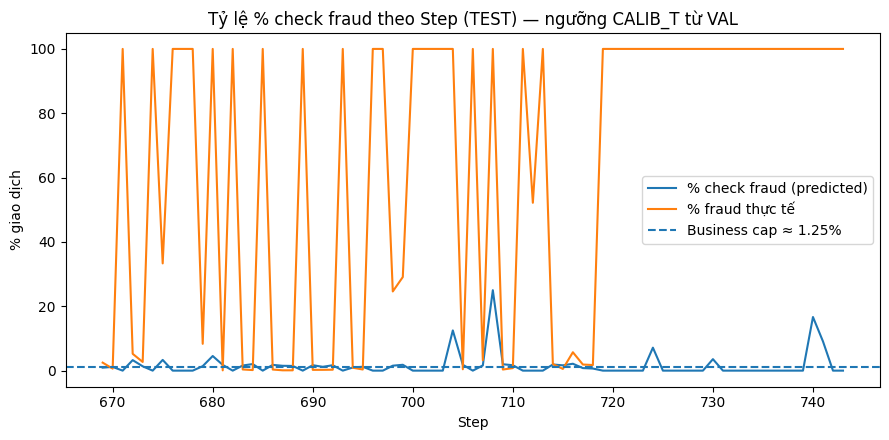

In [ ]:
# Plot: % check fraud theo Step (TEST) với ngưỡng CALIB_T từ VAL
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

# 1) Lấy xác suất TEST (áp temperature nếu có)
z_raw = np.asarray(test_metrics["y_logit"], dtype=np.float32)
y_true = np.asarray(test_metrics["y_true"], dtype=np.int32)

if 'CALIB_SCALER' in globals() and CALIB_SCALER is not None:
    with torch.no_grad():
        z_in = torch.tensor(z_raw, dtype=torch.float32)
        z_cal = CALIB_SCALER(z_in).detach().cpu().numpy()
else:
    z_cal = z_raw

y_prob = 1.0 / (1.0 + np.exp(-z_cal))

# 2) Ngưỡng cố định lấy từ VAL
t = float(CALIB_T)
y_pred = (y_prob >= t).astype(np.int32)

# 3) Ánh xạ TEST_EIDX -> step
test_idx = TEST_EIDX.detach().cpu().numpy() if hasattr(TEST_EIDX, 'detach') else np.asarray(TEST_EIDX)
steps_test = df[C_STEP].to_numpy()[test_idx]

# 4) Gom nhóm theo step -> % predicted và % thực tế
g = pd.DataFrame({"step": steps_test, "y_true": y_true, "y_pred": y_pred}).groupby("step", sort=True)
step_vals = g.size().index.values
pred_rate = g["y_pred"].mean().values * 100.0
true_rate = g["y_true"].mean().values * 100.0
biz_cap = float(CFG.get("business_cap", 0)) * 100.0

# 5) Vẽ
plt.figure(figsize=(9,4.5))
plt.plot(step_vals, pred_rate, label="% check fraud (predicted)")
plt.plot(step_vals, true_rate, label="% fraud thực tế")
if biz_cap > 0:
    plt.axhline(biz_cap, linestyle="--", label=f"Business cap ≈ {biz_cap:.2f}%")
plt.title("Tỷ lệ % check fraud theo Step (TEST) — ngưỡng CALIB_T từ VAL")
plt.xlabel("Step"); plt.ylabel("% giao dịch"); plt.legend(); plt.tight_layout()
